# 08 — Benchmark of the traditional methods

Notebooks 04-07 tried the **4 descriptors of the course** (HOG, LBP, colour histograms, SIFT) with the **3 classifiers** (KNN, SVM, Random Forest): 12 methods, all tested in exactly the same way (same crops, same 5 groups of videos, same video decision).

This notebook puts them side by side to answer:
1. Which method is the best **for each frame** (posture) and **for each video** (fall or no fall)?
2. Why are these two rankings different?
3. Which videos are hard for **all** of them?
4. Does **combining** the descriptors help?
5. Can we **trust** these scores: is the video decision good enough, and do the models look at the person or at the **room**?
6. How do they compare with the depth baseline (02) and the skeleton state machine (10)?
7. Do the scores hold with **new people and new scenes** (strict groups)?

Steps 1-6 only read the scores and predictions saved by notebooks 04-07 (plus the small video decision). Steps 7 and 8 train a few quick KNN classifiers as checks; step 10 trains the 12 methods again.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROC = Path("..") / "data" / "processed"
DESCRIPTORS = {"HOG": "hog", "LBP": "lbp", "Colour (HSV)": "colour", "SIFT (dense, BoVW)": "sift"}
CLASSIFIERS = ["KNN", "SVM", "RF"]
COLOURS = {"HOG": "#2a78d6", "LBP": "#eb6834", "Colour (HSV)": "#1baf7a", "SIFT (dense, BoVW)": "#eda100"}   # one fixed colour per descriptor

scores = pd.read_csv(PROC / "results_traditional.csv")
preds = {d: pd.read_csv(PROC / f"predictions_{short}.csv") for d, short in DESCRIPTORS.items()}
frames = preds["HOG"][["video", "frame", "frame_label"]]
assert all(p[["video", "frame"]].equals(frames[["video", "frame"]]) for p in preds.values())   # same frames, same order
y = frames.frame_label.to_numpy()
print(f"{len(scores)} methods, {len(frames):,} frames, {frames.video.nunique()} videos")

12 methods, 11,027 frames, 70 videos


💡 **Interpretation:** the **12 methods** (4 descriptors × 3 classifiers) and their predictions for the same **11,027 frames** of the **70 videos**, so they can be compared frame by frame and video by video.

## Step 1 — All 12 methods in one table

Sorted by **video accuracy**, because the goal of the project is the video answer: *fall or no fall*.
Two simple references: always answering *not lying* gives a frame accuracy of 0.640; always answering *no fall* gives a video accuracy of 40 / 70 = 0.571.

In [2]:
scores.sort_values(["video accuracy", "macro F1"], ascending=False).reset_index(drop=True)

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,HOG,KNN,0.859,0.799,0.857,0.833,0.833
1,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
2,HOG,RF,0.855,0.770,0.829,0.767,0.821
3,Colour (HSV),RF,0.896,0.842,0.800,0.767,0.767
4,Colour (HSV),KNN,0.883,0.834,0.800,0.767,0.767
5,HOG,SVM,0.859,0.795,0.800,0.733,0.786
6,LBP,RF,0.866,0.796,0.786,0.733,0.759
7,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
8,LBP,KNN,0.867,0.816,0.771,0.767,0.719
9,LBP,SVM,0.873,0.810,0.757,0.733,0.710


💡 **Interpretation:** all 12 methods beat the simple references (0.640 on frames, 0.571 on videos). The best on videos is **HOG + KNN (0.857)**, then colour + SVM (0.843) and HOG + RF (0.829);
the worst is dense SIFT + SVM (0.743). From best to worst there are 8 videos of difference.

## Step 2 — Descriptor or classifier: what matters more?

Each square is one method: rows are descriptors, columns are classifiers. Left: the frame score (macro F1); right: the video score.

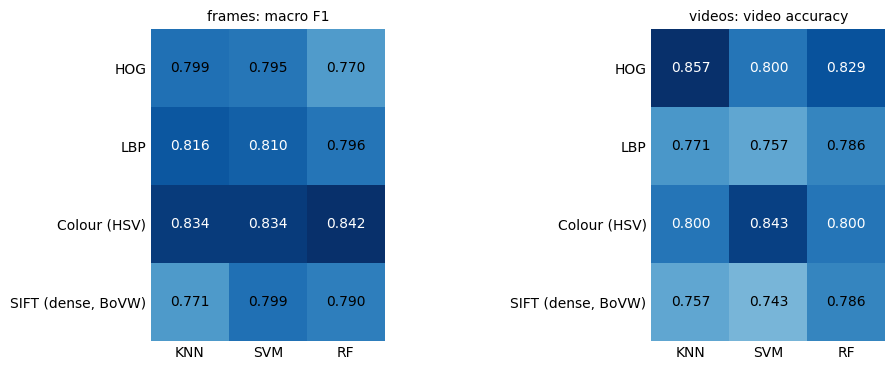

macro F1: gap between the best and worst descriptor (on average) 0.050, between the best and worst classifier 0.010
video accuracy: gap between the best and worst descriptor (on average) 0.067, between the best and worst classifier 0.015


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, column in zip(axes, ["macro F1", "video accuracy"]):
    grid = scores.pivot(index="descriptor", columns="classifier", values=column).loc[list(DESCRIPTORS), CLASSIFIERS]
    ax.imshow(grid, cmap="Blues", vmin=grid.values.min() - 0.1, vmax=grid.values.max())
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            ax.text(c, r, f"{grid.iloc[r, c]:.3f}", ha="center", va="center", fontsize=10,
                    color="white" if grid.iloc[r, c] > grid.values.mean() else "black")
    ax.set_xticks(range(3), CLASSIFIERS); ax.set_yticks(range(4), grid.index)
    ax.set_title(f"{'frames' if column == 'macro F1' else 'videos'}: {column}", fontsize=10)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
plt.tight_layout(); plt.show()

for column in ["macro F1", "video accuracy"]:
    spread = {group: scores.groupby(group)[column].mean().agg(lambda s: s.max() - s.min()) for group in ["descriptor", "classifier"]}
    print(f"{column}: gap between the best and worst descriptor (on average) {spread['descriptor']:.3f}, "
          f"between the best and worst classifier {spread['classifier']:.3f}")

💡 **Interpretation:** the **descriptor matters more than the classifier**: on average, the best and worst descriptors differ by 0.050 (frames) and 0.067 (videos), the best and worst classifiers by only 0.010 and 0.015.
Colour is the best row on frames; on videos, the two best squares are HOG + KNN and colour + SVM.

## Step 3 — Is the best on frames also the best on videos?

Each dot is one method: horizontally its **frame** score (macro F1), vertically its **video** score.
We also measure, for each method, the **gap** in the share of frames predicted *falling* between fall videos and ADL videos (each video counts once, as in the video decision): the bigger the gap, the easier the video decision should be.

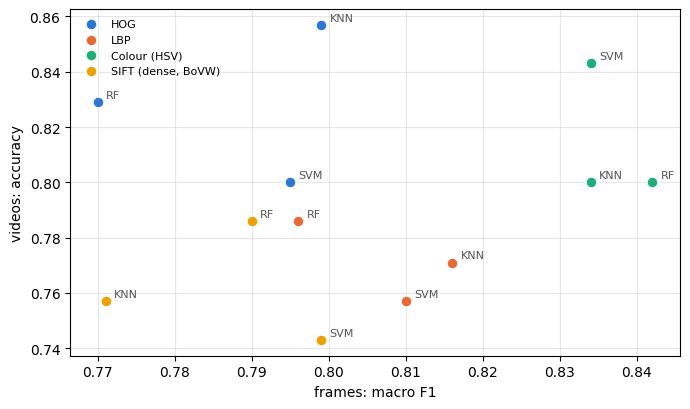

correlation with video accuracy:  frame macro F1 0.16 | falling share gap 0.4


In [4]:
rows = []
for d in DESCRIPTORS:
    for c in CLASSIFIERS:
        falling_share = (preds[d][c] == 0).groupby(frames.video).mean()
        is_fall_video = falling_share.index.str.startswith("fall")
        rows.append({"descriptor": d, "classifier": c,
                     "falling share gap": falling_share[is_fall_video].mean() - falling_share[~is_fall_video].mean()})
check = scores.merge(pd.DataFrame(rows), on=["descriptor", "classifier"])

fig, ax = plt.subplots(figsize=(7, 4.2))
for d in DESCRIPTORS:
    part = check[check.descriptor == d]
    ax.scatter(part["macro F1"], part["video accuracy"], s=70, color=COLOURS[d], label=d, edgecolor="white", linewidth=1.5, zorder=3)
    for _, r in part.iterrows():
        ax.annotate(r["classifier"], (r["macro F1"], r["video accuracy"]), textcoords="offset points", xytext=(6, 3), fontsize=8, color="#555")
ax.set_xlabel("frames: macro F1"); ax.set_ylabel("videos: accuracy")
ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()
print("correlation with video accuracy:  frame macro F1", round(check["macro F1"].corr(check["video accuracy"]), 2),
      "| falling share gap", round(check["falling share gap"].corr(check["video accuracy"]), 2))

💡 **Interpretation:** **almost no link** between the two scores (correlation 0.16): colour + RF is the best on frames but only 0.800 on videos, while HOG + KNN is average on frames but the best on videos.
The *falling* share gap has a weak link too (0.40). With only 12 methods these correlations are rough; step 4 looks for a better explanation.

## Step 4 — How good is the video decision itself? (a test with perfect postures)

Our video answer has two stages: *postures of the frames* → *shares* → *logistic regression*. Which stage limits the result?
Test: we give the second stage **perfect postures** (the true labels) instead of predictions. No descriptor is used at all.

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

def video_decision(frame_pred):   # same function as notebooks 04-07
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

share, y_video, perfect = video_decision(y)
perfect_accuracy = accuracy_score(y_video, perfect)
print(f"perfect postures: video accuracy {perfect_accuracy:.3f} ({(perfect == y_video).sum()}/70), recall {recall_score(y_video, perfect):.3f}")
print("wrong videos:", list(share.index[perfect != y_video]))
falling = frames[frames.frame_label == 0]
print("'falling' frames:", falling.video.str.startswith("adl").sum(), "in ADL videos,", falling.video.str.startswith("fall").sum(), "in fall videos")

perfect postures: video accuracy 0.800 (56/70), recall 0.767
wrong videos: ['adl-21', 'adl-31', 'adl-32', 'adl-33', 'adl-34', 'adl-35', 'adl-38', 'fall-01', 'fall-03', 'fall-05', 'fall-07', 'fall-09', 'fall-10', 'fall-11']
'falling' frames: 817 in ADL videos, 900 in fall videos


💡 **Interpretation:** even **perfect postures give only 0.800 (56/70)**, so the **video decision is the weak stage**: 817 *falling* frames are ADLs (going down), and long falls have small shares.
HOG + KNN (60/70) is above this, so part of its lead comes from posture **mistakes** that happen to help: the video ranking does not tell us which descriptor is best.

## Step 5 — Video by video: which videos are hard for everyone?

For each descriptor we take its **best classifier for videos** and redo the video decision of notebooks 04-07 (same code), to know which videos it gets wrong.

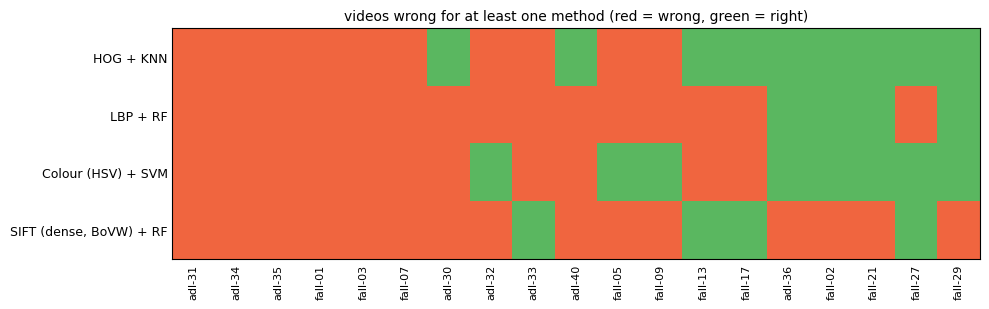

19 of 70 videos are wrong for at least one method; wrong for all 4: ['adl-31', 'adl-34', 'adl-35', 'fall-01', 'fall-03', 'fall-07']


In [6]:
best_of = (scores.sort_values(["video accuracy", "macro F1"], ascending=False).groupby("descriptor", sort=False).head(1)
           .set_index("descriptor").classifier.loc[list(DESCRIPTORS)])
correct = {}
for d, c in best_of.items():
    share, y_video, video_pred = video_decision(preds[d][c].to_numpy())
    correct[f"{d} + {c}"] = pd.Series(video_pred == y_video, index=share.index)
correct = pd.DataFrame(correct)
hard = correct[~correct.all(axis=1)]
hard = hard.loc[hard.sum(axis=1).sort_values(kind="stable").index]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(hard.T.astype(int), cmap="RdYlGn", vmin=-0.3, vmax=1.3, aspect="auto")
ax.set_xticks(range(len(hard)), hard.index, rotation=90, fontsize=8); ax.set_yticks(range(4), hard.columns, fontsize=9)
ax.set_title("videos wrong for at least one method (red = wrong, green = right)", fontsize=10); ax.tick_params(length=0)
plt.tight_layout(); plt.show()
print(f"{len(hard)} of 70 videos are wrong for at least one method; wrong for all 4: {list(hard.index[hard.sum(axis=1) == 0])}")

💡 **Interpretation:** **51 of 70 videos** are right for all 4 methods. **6 are wrong for all**: `adl-31`, `adl-34`, `adl-35` (people going down to the floor) and `fall-01`, `fall-03`, `fall-07` (long fall videos).
**All 6 are also wrong with perfect postures** (step 4): this is the limit of the shares, not of one descriptor.

## Step 6 — Does combining the descriptors help? (majority vote)

Each descriptor sees something different (shape, texture, colour, local patterns). A simple way to combine them: for every frame, the **4 best methods vote** and the posture with the most votes wins.
If there is a tie, we follow HOG, the best method on videos. The 4 predictions come from the same video-level tests. But the 4 voters were **chosen with their test scores**, so this result is slightly optimistic.

In [7]:
votes = np.stack([preds[d][c].to_numpy() for d, c in best_of.items()], axis=1)
vote = []
for row in votes:
    values, counts = np.unique(row, return_counts=True)
    winners = values[counts == counts.max()]
    vote.append(winners[0] if len(winners) == 1 else row[0])   # tie -> follow HOG (first column)
vote = np.array(vote)

share, y_video, video_pred = video_decision(vote)
vote_scores = {"descriptor": "Vote of the 4", "classifier": "-", "frame accuracy": accuracy_score(y, vote),
               "macro F1": f1_score(y, vote, average="macro"), "video accuracy": accuracy_score(y_video, video_pred),
               "recall (falls)": recall_score(y_video, video_pred), "precision (falls)": precision_score(y_video, video_pred)}
pd.concat([scores.merge(best_of.rename("classifier").reset_index(), on=["descriptor", "classifier"]),
           pd.DataFrame([vote_scores])], ignore_index=True).round(3)

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,LBP,RF,0.866,0.796,0.786,0.733,0.759
1,HOG,KNN,0.859,0.799,0.857,0.833,0.833
2,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
3,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
4,Vote of the 4,-,0.906,0.859,0.814,0.800,0.774


💡 **Interpretation:** the vote gives the **best frames of all** (accuracy 0.906, macro F1 0.859), but only **0.814 on videos** (57/70), below HOG + KNN alone (0.857).
This fits step 4: its postures are the best, and its video score (57) is close to the one of perfect postures (56).

## Step 7 — Person or background? The same border test for three descriptors

Notebook 06 tested colour on the **centre** or the **border** of the crop only. A fair comparison needs the same test for the others.
We hide one part of the crop (black), recompute the descriptor, and classify with KNN. (SIFT is left out: each of its descriptors sees nearly the whole crop.)

Limit of the test: the person fills most of the crop, so the **border holds the head and feet too**. It cannot fully separate person and background.

In [8]:
import cv2
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import PredefinedSplit
from sklearn.neighbors import KNeighborsClassifier

z = np.load(PROC / "crops64.npz")
crops_of = {key: crop for key, crop in zip(zip(z["video"].tolist(), z["frame"].tolist()), z["crops"])}
crops = np.stack([crops_of[key] for key in zip(frames.video, frames.frame)])
fold_of = {}
videos = np.array(sorted(frames.video.unique()))
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for k, (_, test) in enumerate(splitter.split(videos, np.char.startswith(videos.astype(str), "fall").astype(int))):
    fold_of.update({v: k for v in videos[test]})
cv = PredefinedSplit(frames.video.map(fold_of).to_numpy())

def regions(image, n=4):
    side = image.shape[0] // n
    return [np.ascontiguousarray(image[a * side:(a + 1) * side, b * side:(b + 1) * side]) for a in range(n) for b in range(n)]

def describe(image, name):   # the same descriptors as notebooks 04, 05 and 06
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    if name == "HOG":
        return hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    if name == "LBP":
        codes = local_binary_pattern(gray, P=8, R=1, method="nri_uniform").astype(int)
        return np.hstack([np.bincount(r.ravel(), minlength=59) / r.size for r in regions(codes)])
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return np.hstack([cv2.calcHist([r], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel() / r[..., 0].size for r in regions(hsv)])

centre = np.zeros((64, 64, 1), np.uint8); centre[16:48, 16:48] = 1
rows = []
for name in ["HOG", "LBP", "Colour (HSV)"]:
    row = {"descriptor": name}
    for part, mask in [("whole crop", np.ones_like(centre)), ("border only", 1 - centre), ("centre only", centre)]:
        X = np.stack([describe(np.ascontiguousarray(c * mask), name) for c in crops]).astype(np.float32)
        row[part] = accuracy_score(y, cross_val_predict(KNeighborsClassifier(n_neighbors=5), X, y, cv=cv))
    rows.append(row)
pd.DataFrame(rows).round(3)

,descriptor,whole crop,border only,centre only
0,HOG,0.859,0.862,0.759
1,LBP,0.867,0.850,0.813
2,Colour (HSV),0.883,0.868,0.832


💡 **Interpretation:** the **border alone** is as good as the whole crop for HOG (0.862 vs 0.859) and nearly as good for colour (0.868 vs 0.883); the centre is always worse.
So the test does **not** show that colour uses the room more than HOG does. It cannot tell whether the border helps through the background or through the head and feet.

## Step 8 — How strong is the room shortcut?

The dataset may have a trap: are falls and daily activities filmed in **different rooms**? We look at one image per type, then test the room alone:
for each video we build the **background** (the median of its frames, where a moving person disappears) and give it to a 1-nearest-neighbour classifier, with the same 5 video groups.
A person who stays still can remain in the background, so we only use the **top-left corner** (red rectangle), where people are rarely seen.

frames where the person's box touches this corner: 3.9%


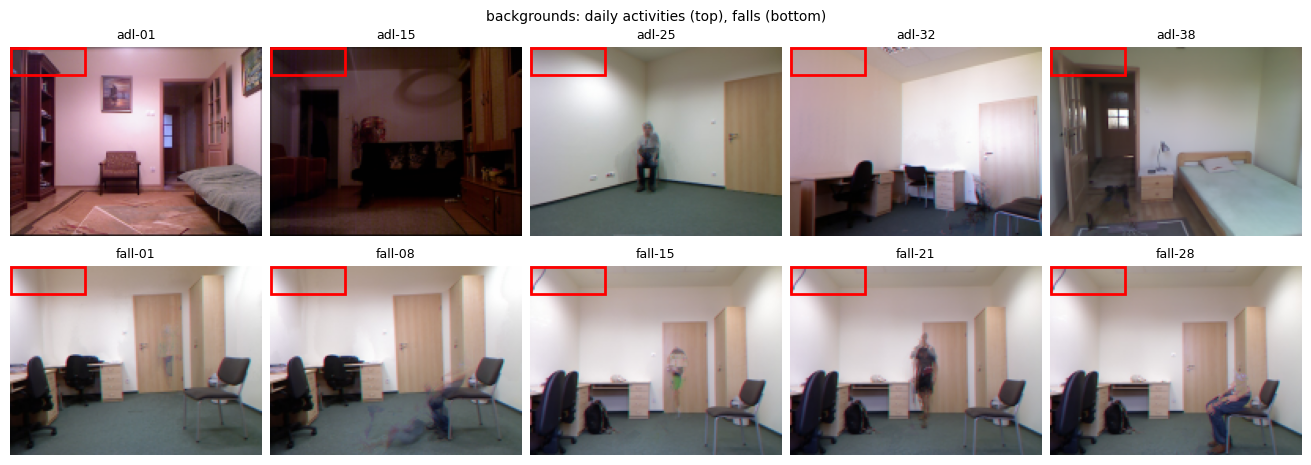

corner of the room only: 70/70 videos right


In [9]:
ROOT = Path("..") / "data" / "raw" / "urfd" / "rgb"
background = {}
for v in videos:
    files = sorted((ROOT / v).rglob("*.png"))[::10]
    background[v] = np.median([cv2.resize(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB), (160, 120), interpolation=cv2.INTER_AREA)
                               for f in files], axis=0).astype(np.uint8)

CORNER = (slice(0, 18), slice(0, 48))      # 48 x 18 pixels of the 160 x 120 background
boxes = pd.read_csv(PROC / "person_boxes.csv").dropna()
print(f"frames where the person's box touches this corner: {((boxes.x < 192) & (boxes.y < 72)).mean():.1%}")

fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), layout="constrained")
for ax, v in zip(axes.flat, ["adl-01", "adl-15", "adl-25", "adl-32", "adl-38", "fall-01", "fall-08", "fall-15", "fall-21", "fall-28"]):
    ax.imshow(background[v]); ax.set_title(v, fontsize=9); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 47, 17, fill=False, edgecolor="red", linewidth=2))
plt.suptitle("backgrounds: daily activities (top), falls (bottom)", fontsize=10); plt.show()

X_room = np.array([background[v][CORNER].ravel() for v in videos]) / 255
y_room = np.array([v.startswith("fall") for v in videos]).astype(int)
room_pred = cross_val_predict(KNeighborsClassifier(n_neighbors=1), X_room, y_room, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
room_accuracy = accuracy_score(y_room, room_pred)
print(f"corner of the room only: {(room_pred == y_room).sum()}/70 videos right")

💡 **Interpretation:** **70 of 70 videos right from a corner of the image**, without looking at the fall: all the falls are filmed from similar views of one office, and most ADLs in other rooms.
So a high score from any model that sees the background proves nothing here; our posture → shares pipeline is protected only partly.

## Step 9 — All the scores together (random groups)

All use the same 70 videos, but **not in the same way**, so this is not a strict ranking:
- **02, depth baseline:** mean / min / max over the video of 8 features measured with a **depth camera** (another sensor), with the same 5 video groups;
- **10, state machine:** rules on skeletons over time. No training, but its thresholds were chosen **by hand on these same videos** (optimistic);
- **04-07:** the best classifier of each descriptor was chosen **with its test score** (slightly optimistic too);
- **checks** (step 4 and step 8): perfect postures, and the room alone. They are not methods to use.

Note: with 70 videos, **one video = 1.4 points** of accuracy, so differences of 1-2 points are only 1 video.

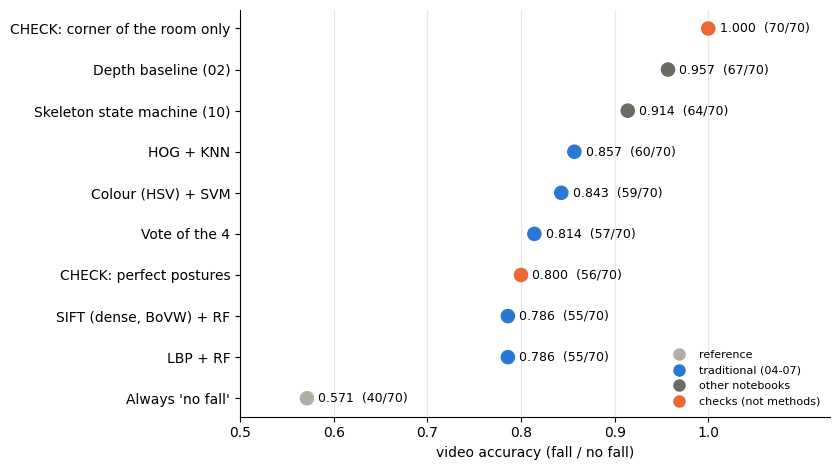

In [10]:
ranking = pd.DataFrame([
    {"method": "Always 'no fall'", "family": "reference", "video accuracy": 40 / 70},
    *[{"method": f"{d} + {c}", "family": "traditional (04-07)",
       "video accuracy": scores.set_index(["descriptor", "classifier"]).loc[(d, c), "video accuracy"]} for d, c in best_of.items()],
    {"method": "Vote of the 4", "family": "traditional (04-07)", "video accuracy": vote_scores["video accuracy"]},
    {"method": "CHECK: perfect postures", "family": "checks (not methods)", "video accuracy": perfect_accuracy},
    {"method": "CHECK: corner of the room only", "family": "checks (not methods)", "video accuracy": room_accuracy},
    {"method": "Skeleton state machine (10)", "family": "other notebooks", "video accuracy": 0.914},   # notebook 10
    {"method": "Depth baseline (02)", "family": "other notebooks", "video accuracy": 0.957},          # notebook 02
]).sort_values("video accuracy")
family_colour = {"reference": "#b0aea5", "traditional (04-07)": "#2a78d6", "other notebooks": "#6b6a63", "checks (not methods)": "#eb6834"}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.scatter(ranking["video accuracy"], ranking.method, s=90, color=ranking.family.map(family_colour), zorder=3)   # dots, not bars:
for k, value in enumerate(ranking["video accuracy"]):                                                            # the axis does not start at 0
    ax.text(value + 0.012, k, f"{value:.3f}  ({round(value * 70)}/70)", va="center", fontsize=9)
ax.set_xlim(0.5, 1.13); ax.set_xticks(np.arange(0.5, 1.01, 0.1)); ax.set_xlabel("video accuracy (fall / no fall)"); ax.grid(axis="x", alpha=0.3)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=c) for c in family_colour.values()], labels=list(family_colour),
          fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

💡 **Interpretation:** **HOG + KNN gets 60 of 70 videos right**, the state machine 64, the depth baseline 67. A **corner of the room alone gets 70**: on this dataset, a perfect score can mean *recognising the room*.
Our traditional methods cannot copy that score directly: their video decision only sees 3 posture shares.

## Step 10 — A stricter test: new people and new scenes

Until now, the 5 groups were made **at random**: the same person, clothes and room can be in training **and** in test. Here we use other groups (`video_groups.csv`), so that the test is closer to a new situation:
- each **ADL recording session** (same room, same light) stays in one group;
- each **block of 6 falls with the same clothes** stays in one group;
- the videos with exactly the same blue T-shirt (`adl-34`, `adl-35`, `fall-07` … `fall-12`) are in the same group.

**Limits:** the groups were made by looking at rooms and clothes (a person who changed clothes may still be in two groups), and **all the falls are in the same office**, so the fall room is never really new.

In [11]:
groups = pd.read_csv(Path("..") / "video_groups.csv")
group_of = groups.set_index("video").group
strict = frames.video.map(group_of).to_numpy()
table = groups.assign(kind=np.where(groups.video.str.startswith("fall"), "falls", "ADLs")).groupby(["group", "kind"]).size().unstack()
table["labelled frames"] = pd.Series(strict).value_counts()
assert len(groups) == 70 and set(groups.video) == set(videos)
table

kind,ADLs,falls,labelled frames
group,,,
1,11,6,2953
2,12,6,2803
3,6,6,1007
4,6,6,2341
5,5,6,1923


💡 **Interpretation:** every group has **6 falls** and 5 to 12 ADLs, but the sizes differ a lot (1,007 to 2,953 frames).
The test of each group is now on recording sessions and fall clothes that the model has **not seen** in training.

We train the **same 12 methods** again (same descriptors, same settings), only with the new groups: train on 4 groups, test on the 5th. This takes several minutes, so the predictions are saved and loaded the next time.

In [12]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import MiniBatchKMeans

STRICT = PROC / "predictions_strict.csv"
if not STRICT.exists():
    sift = cv2.SIFT_create()
    keypoints = [cv2.KeyPoint(float(a), float(b), 16) for b in range(8, 64, 8) for a in range(8, 64, 8)]
    sift_all = np.stack([sift.compute(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), keypoints)[1] for c in crops]).astype(np.float32)

    def sift_words(train, K=300):   # vocabulary learnt on the training groups only (notebook 07)
        sample = sift_all[train].reshape(-1, 128)
        sample = sample[np.random.default_rng(0).choice(len(sample), 100_000, replace=False)]
        vocabulary = MiniBatchKMeans(n_clusters=K, n_init=3, batch_size=4096, random_state=0).fit(sample)
        words = vocabulary.predict(sift_all.reshape(-1, 128)).reshape(len(sift_all), -1)
        return np.stack([np.bincount(w, minlength=K) for w in words]) / words.shape[1]

    fixed = {name: np.stack([describe(c, name) for c in crops]) for name in ["HOG", "LBP", "Colour (HSV)"]}
    out = frames.copy()
    for g in range(1, 6):
        train, test = strict != g, strict == g
        for d in DESCRIPTORS:
            X = fixed[d] if d in fixed else sift_words(train)
            for c, model in {"KNN": KNeighborsClassifier(n_neighbors=5), "SVM": SVC(kernel="rbf"),
                             "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)}.items():
                out.loc[test, f"{d} + {c}"] = model.fit(X[train], y[train]).predict(X[test])
    out.to_csv(STRICT, index=False)
strict_pred = pd.read_csv(STRICT)
assert strict_pred[["video", "frame"]].equals(frames[["video", "frame"]])

def strict_video_decision(frame_pred):   # same decision as before, but with the new groups
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return share, y_video, cross_val_predict(model, share, y_video, cv=PredefinedSplit(share.index.map(group_of).to_numpy()))

rows = []
for r in scores.itertuples(index=False):
    p = strict_pred[f"{r.descriptor} + {r.classifier}"].astype(int).to_numpy()
    share, y_video, v = strict_video_decision(p)
    rows.append({"descriptor": r.descriptor, "classifier": r.classifier, "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro"),
                 "video accuracy": accuracy_score(y_video, v), "recall (falls)": recall_score(y_video, v), "precision (falls)": precision_score(y_video, v)})
strict_scores = pd.DataFrame(rows).round(3)
strict_scores.to_csv(PROC / "results_traditional_strict.csv", index=False)
both = scores.merge(strict_scores, on=["descriptor", "classifier"], suffixes=(" (random)", " (strict)"))
both[["descriptor", "classifier"] + [f"{m} ({g})" for m in ["frame accuracy", "macro F1", "video accuracy"]
                                     for g in ["random", "strict"]]].sort_values("macro F1 (strict)", ascending=False).round(3).reset_index(drop=True)

,descriptor,classifier,frame accuracy (random),frame accuracy (strict),macro F1 (random),macro F1 (strict),video accuracy (random),video accuracy (strict)
0,Colour (HSV),SVM,0.886,0.784,0.834,0.662,0.843,0.957
1,HOG,SVM,0.859,0.749,0.795,0.639,0.800,0.843
2,LBP,SVM,0.873,0.727,0.810,0.621,0.757,0.671
3,Colour (HSV),KNN,0.883,0.726,0.834,0.614,0.800,0.786
4,Colour (HSV),RF,0.896,0.756,0.842,0.607,0.800,0.900
5,LBP,KNN,0.867,0.670,0.816,0.593,0.771,0.600
6,HOG,KNN,0.859,0.710,0.799,0.591,0.857,0.871
7,HOG,RF,0.855,0.727,0.770,0.588,0.829,0.729
8,LBP,RF,0.866,0.716,0.796,0.576,0.786,0.829
9,"SIFT (dense, BoVW)",SVM,0.866,0.694,0.799,0.563,0.743,0.786


💡 **Interpretation:** the frame scores **drop a lot for all 12 methods**: the best macro F1 goes from 0.842 to **0.662** (colour + SVM), and HOG + KNN from 0.799 to 0.591. The random groups were too optimistic.
The video scores move in **both directions**, and colour + SVM even jumps from 0.843 to **0.957** with worse postures: step 11 looks for the reason.

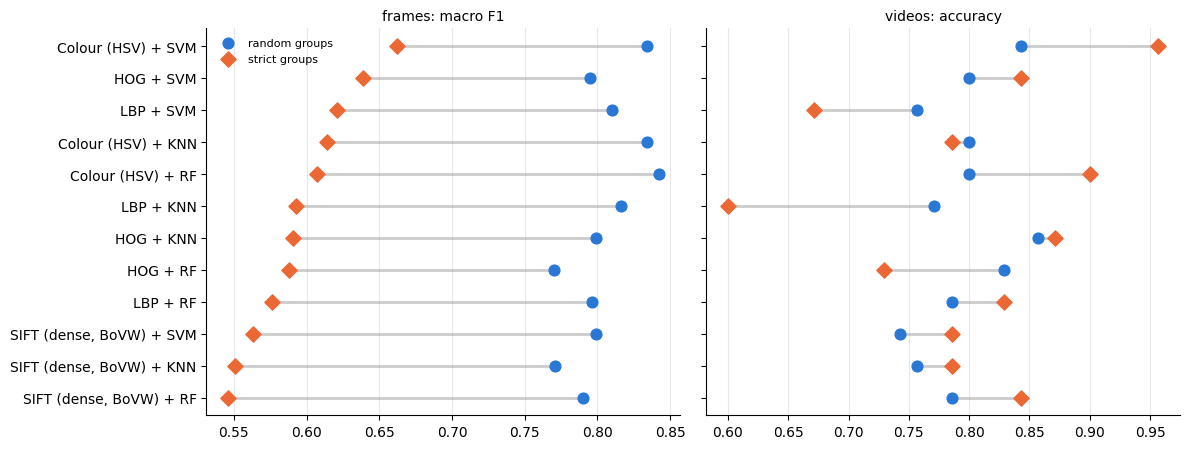

share of each posture recognised, average of the 12 methods: {'not lying': 0.87, 'falling': 0.43, 'lying': 0.45}
accuracy per test group, average of the 12 methods: {1: 0.84, 2: 0.72, 3: 0.87, 4: 0.57, 5: 0.6}
always 'not lying', per test group: {1: 0.75, 2: 0.84, 3: 0.74, 4: 0.45, 5: 0.36}
perfect postures, strict groups: 57/70
corner of the room only, strict groups: 65/70


In [13]:
order = both.sort_values("macro F1 (strict)")
method = order.descriptor + " + " + order.classifier
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, m in zip(axes, ["macro F1", "video accuracy"]):
    ax.hlines(method, order[f"{m} (strict)"], order[f"{m} (random)"], color="#cccccc", linewidth=2, zorder=1)
    ax.scatter(order[f"{m} (random)"], method, s=60, color="#2a78d6", label="random groups", zorder=3)
    ax.scatter(order[f"{m} (strict)"], method, s=60, color="#eb6834", marker="D", label="strict groups", zorder=3)
    ax.set_title("frames: macro F1" if m == "macro F1" else "videos: accuracy", fontsize=10)
    ax.grid(axis="x", alpha=0.3)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

each = strict_pred[list(method)]
print("share of each posture recognised, average of the 12 methods:",
      {PHASE: round(float((each[y == k] == k).mean().mean()), 2) for k, PHASE in [(-1, "not lying"), (0, "falling"), (1, "lying")]})
print("accuracy per test group, average of the 12 methods:", {g: round(float(each[strict == g].eq(y[strict == g], axis=0).mean().mean()), 2) for g in range(1, 6)})
print("always 'not lying', per test group:", {g: round(float(np.mean(y[strict == g] == -1)), 2) for g in range(1, 6)})
print(f"perfect postures, strict groups: {(strict_video_decision(y)[2] == y_video).sum()}/70")
room_strict = cross_val_predict(KNeighborsClassifier(n_neighbors=1), X_room, y_room, cv=PredefinedSplit(np.array([group_of[v] for v in videos])))
print(f"corner of the room only, strict groups: {(room_strict == y_room).sum()}/70")

💡 **Interpretation:** *falling* and *lying* are recognised in only **43% and 45%** of their frames, and groups 2, 4 and 5 are hard (group 2 is even below always saying *not lying*: 0.72 vs 0.84).
Perfect postures still give only **57/70**, and the corner of the room still answers **65/70**, because all the falls are in the same office.

## Step 11 — Why can a method with worse postures get better video scores?

In the strict groups, the ADL rooms are **new** for the model, but the office of the falls is **always** in the training set. So we measure the share of frames recognised for each posture, separately in **ADL videos** and in **fall videos**.

In [14]:
rows = []
fall_frame = frames.video.str.startswith("fall").to_numpy()
for r in scores.itertuples(index=False):
    for name, p in [("random", preds[r.descriptor][r.classifier].to_numpy()),
                    ("strict", strict_pred[f"{r.descriptor} + {r.classifier}"].astype(int).to_numpy())]:
        row = {"method": f"{r.descriptor} + {r.classifier}", "groups": name}
        for kind, mask in [("ADL", ~fall_frame), ("fall", fall_frame)]:
            for k, label in [(0, "falling"), (1, "lying")]:
                row[f"{label} in {kind} videos"] = np.mean(p[mask & (y == k)] == k)
        rows.append(row)
seen = pd.DataFrame(rows).set_index(["groups", "method"])
print("average of the 12 methods:")
print(seen.groupby("groups").mean().round(2).T)
seen.loc["strict"].round(2)

average of the 12 methods:
groups                  random  strict
falling in ADL videos     0.61    0.18
lying in ADL videos       0.79    0.27
falling in fall videos    0.71    0.66
lying in fall videos      0.79    0.72


,falling in ADL videos,lying in ADL videos,falling in fall videos,lying in fall videos
method,,,,
LBP + KNN,0.43,0.43,0.67,0.77
LBP + SVM,0.35,0.31,0.68,0.72
LBP + RF,0.05,0.25,0.55,0.71
HOG + KNN,0.13,0.27,0.67,0.73
HOG + SVM,0.16,0.35,0.72,0.76
HOG + RF,0.08,0.24,0.59,0.72
Colour (HSV) + KNN,0.09,0.41,0.68,0.74
Colour (HSV) + SVM,0.00,0.34,0.72,0.75
Colour (HSV) + RF,0.10,0.13,0.71,0.74


💡 **Interpretation:** with strict groups the methods still see *falling* and *lying* in the **known office**, but hardly in **new ADL rooms**. Colour + SVM: *falling* 72% in fall videos, **0% in ADLs**.
Then ADLs get no *falling* frames and look like "no fall": its 0.957 comes from **missing** the postures of ADLs. Video accuracy alone is misleading here.

## Conclusion of the traditional part

1. **Frames, random groups:** scores look good (best single method: colour + RF, accuracy 0.896, macro F1 0.842; vote of 4: 0.906). **Frames, strict groups:** they drop for all 12 methods (best macro F1 **0.662**, colour + SVM; HOG + SVM 0.639).
   The strict scores are the more honest estimate for new people and scenes.
2. **Videos: no reliable winner.** With random groups HOG + KNN is first (60/70), one video before colour + SVM; perfect postures give only 56/70. With strict groups colour + SVM gets 67/70, but by **not recognising** people who go down in new rooms (step 11).
   So we do **not** choose a method by its video accuracy.
3. **The descriptor matters more than the classifier** with random groups (average gaps of 0.05-0.07 vs 0.01-0.015).
4. **The video decision is too weak:** shares of postures lose the **order and speed** of events. The 6 videos that all 4 methods get wrong are also wrong with perfect postures. Part B needs **time**.
5. **The dataset has a room shortcut:** a corner of the image, almost never containing the person, answers 70/70 (65/70 with strict groups), because all the falls are in one office. A perfect score can mean *recognising the room*.
6. **Limits:** settings (grid, number of words, voters) were chosen on the random test groups; when the video decision is trained, the posture models behind its inputs had already seen the test videos (small leak); the strict groups were made by looking at rooms and clothes;
   one video = 1.4 points.

**For part B (notebooks 09-13):** use the **strict groups** as the main test (and the random ones to compare with part A), judge the models on **macro F1 and on ADL and fall videos separately**, predict **postures** (not fall / no fall directly), and choose settings on validation videos.
The traditional scores to beat with strict groups are **0.662** (macro F1, colour + SVM) and **0.784** (accuracy, colour + SVM).